# Lab 4, Notebook B - Aligning point clouds

*Linear Algebra for Data Science, UCU 2026. Uses Session 5.2 (the SVD, orthogonal Procrustes $Q = UV^\top$, the Kabsch sign fix) and, for B3(d), PCA from Session 5.1.*

A 3-D scanner, a depth camera or a robot's lidar sees an object in its own coordinate system. Before two scans can be compared, merged or used to locate the robot, they must be brought into one frame by a **rigid motion**: a rotation and a translation. When we know which point corresponds to which, the best rotation comes from one $3\times3$ SVD (B1). When the data are nearly flat, that SVD can return a mirror image instead of a rotation, and we must forbid it (B2). When we do not know the correspondences at all, we guess them, align, and guess again: the **iterative closest point** algorithm (B3). Each step of ICP is the problem of B1.

**Convention (as in Lecture 5.2 and the notes).** Points are the **rows** of a matrix. A rigid motion maps the rows of $X$ to the rows of $XQ + \mathbf 1\mathbf t^\top$, with $Q$ orthogonal and $\mathbf t\in\mathbb R^3$. On a single **column** vector $\mathbf x$ the same motion is $\mathbf x\mapsto Q^\top\mathbf x + \mathbf t$. If $X^\top Y = U\Sigma V^\top$ (both clouds centred), the best orthogonal $Q$ is $UV^\top$.

**How to work.** Most tasks ask you to **predict first, in writing, then compute, then explain any difference**. Write the prediction *before* running the cell. A wrong prediction with an honest explanation earns more at the defence than a correct number you cannot explain.

**Rules.**
- Do not call `np.linalg.inv` or `np.linalg.pinv` anywhere.
- Compute every rotation with `np.linalg.svd` on a $3\times3$ matrix. `scipy.linalg.orthogonal_procrustes` and `scipy.spatial.transform.Rotation` are allowed only where a cell says **check**.
- Find nearest neighbours with `scipy.spatial.cKDTree`.
- Do not change the seeds.
- Before you submit, run `Kernel -> Restart & Run All`.

**Marking.** Core B is worth 2 points at the defence; the code point and the extension are shared with Notebook A.

**Contents.** B1 Procrustes with known correspondences | B2 When the best fit is a mirror: Kabsch | B3 Unknown correspondences: ICP | Extension E2 (shape from a moving camera: Tomasi-Kanade). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Liubomyr Smerek* |
| **Team member 2** | *Oleksandr Korniienko* |
| **Extension attempted** (at most one in the whole lab) | *none* |
| **Late days used on this lab** | *0* |
| **Runs top to bottom from a clean kernel** | *yes* |

python 3.14.7 | numpy 2.4.6 | scipy 1.18.1 | matplotlib 3.11.2
model: (800, 3)  centred singular values / sqrt(n): [1.3033 0.5768 0.3731]


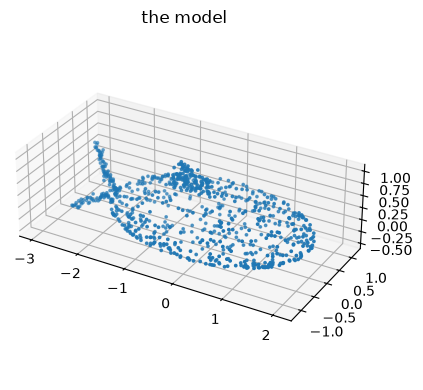

In [1]:
import sys, time
import numpy as np
import scipy, scipy.linalg as sl
from scipy.spatial import cKDTree
import matplotlib, matplotlib.pyplot as plt

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)
np.set_printoptions(precision=4, suppress=True, linewidth=110)


def make_fish(n, seed):
    # n points on the surface of an asymmetric 'fish': an ellipsoid body, a fin on top, a forked tail bent to one side
    rng = np.random.default_rng(seed)
    nb, nf = int(0.7 * n), int(0.15 * n); nt = n - nb - nf
    z = rng.standard_normal((nb, 3)); z /= np.linalg.norm(z, axis=1, keepdims=True)
    body = z * np.array([2.0, 1.2, 0.5])
    a, b = rng.random(nf), rng.random(nf); m = a + b > 1; a[m], b[m] = 1 - a[m], 1 - b[m]
    P0, P1, P2 = np.array([0.3, 0, 0.5]), np.array([-0.9, 0, 0.45]), np.array([-0.6, 0, 1.1])
    fin = P0 + a[:, None] * (P1 - P0) + b[:, None] * (P2 - P0) + 0.03 * rng.standard_normal((nf, 3))
    s = rng.random(nt); side = np.where(rng.random(nt) < 0.5, 1, -1)
    tail = np.c_[-2.0 - 0.9 * s, 0.25 * s + 0.5 * side * s ** 1.5, 0.45 * side * s] + 0.04 * rng.standard_normal((nt, 3))
    return np.vstack([body, fin, tail])


def rot(axis, deg):
    # rotation by deg degrees about axis, ACTING ON COLUMN VECTORS: x -> R x (Rodrigues' formula)
    k = np.asarray(axis, float); k /= np.linalg.norm(k); th = np.deg2rad(deg)
    K = np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def angle_deg(Q):
    # rotation angle of a 3x3 rotation matrix, in degrees: trace Q = 1 + 2 cos(angle)
    return np.degrees(np.arccos(np.clip((np.trace(Q) - 1) / 2, -1, 1)))


def rms(A, B):
    # root-mean-square distance between corresponding rows of A and B
    return np.sqrt(np.mean(np.sum((A - B) ** 2, axis=1)))


def show(*clouds, labels=None, title=""):
    fig = plt.figure(figsize=(5.5, 4)); ax = fig.add_subplot(projection="3d")
    for i, C in enumerate(clouds):
        ax.scatter(*C.T, s=3, label=None if labels is None else labels[i])
    ax.set_box_aspect(np.ptp(np.vstack(clouds), axis=0)); ax.set_title(title)
    if labels: ax.legend()
    plt.tight_layout(); plt.show()


X = make_fish(800, seed=1)            # the model: 800 points, rows are points
n = len(X)
print("model:", X.shape, " centred singular values / sqrt(n):", np.linalg.svd(X - X.mean(0), compute_uv=False) / np.sqrt(n))
show(X, title="the model")

---
## B1. Procrustes with known correspondences

A scanner has measured the same 800 points, in the same order, after the fish was moved. The manual says the motion was the rotation $R$ by $40^\circ$ about the axis $(1,2,2)$, acting on column vectors as $\mathbf x\mapsto R\mathbf x$, followed by the shift $\mathbf t = (5,-2,1)$. The measurements carry noise of size $\text{sd} = 0.02$ per coordinate.

**(a)** In our row convention the planted motion is $Y = XQ_{\text{true}} + \mathbf 1\mathbf t^\top + E$. Which matrix is $Q_{\text{true}}$, in terms of $R$? Then implement `procrustes(X, Y)`, which centres both clouds, computes the SVD of the $3\times3$ matrix $\widetilde X^\top\widetilde Y$, and returns $Q = UV^\top$, the translation $\mathbf t$, and the singular values. (Section 2 of Tutorial 5.2 proves that $UV^\top$ is optimal; here you only use it.)

In [2]:
R_true = rot([1, 2, 2], 40)
t_true = np.array([5.0, -2.0, 1.0])
sd = 0.02

In [3]:
Q_true = R_true.T   # y = R x + t on columns  ->  y^T = x^T R^T + t^T on rows

def procrustes(X, Y):
    # returns Q (orthogonal), t, s (singular values of the centred X'Y) with  X Q + 1 t' ~ Y
    mx, my = X.mean(0), Y.mean(0)
    U, s, Vt = np.linalg.svd((X - mx).T @ (Y - my))   # 3x3 SVD
    Q = U @ Vt
    t = my - mx @ Q
    return Q, t, s

In [4]:
# check
Y = X @ Q_true + t_true + sd * np.random.default_rng(2).standard_normal(X.shape)
Q, t, s = procrustes(X, Y)
R_sp, _ = sl.orthogonal_procrustes(X - X.mean(0), Y - Y.mean(0))
assert np.allclose(Q, R_sp) and np.allclose(Q.T @ Q, np.eye(3))
print(f"det Q = {np.linalg.det(Q):+.0f};  rotation error {angle_deg(Q @ Q_true.T):.3f} deg;  "
      f"translation error {np.linalg.norm(t - t_true):.4f}")

det Q = +1;  rotation error 0.064 deg;  translation error 0.0014


**(b)** *Predict, then compute.* Lecture 5.2 gives the minimal value
$$\min_Q\|\widetilde XQ - \widetilde Y\|_F^2 = \|\widetilde X\|_F^2 + \|\widetilde Y\|_F^2 - 2(\sigma_1+\sigma_2+\sigma_3).$$
Predict two things before running: whether the residual of your fit will equal this formula exactly or only approximately, and the size of the **mean squared residual per point**, $\frac1n\|XQ + \mathbf 1\mathbf t^\top - Y\|_F^2$, in terms of $\text{sd}$. Then compute both.

**Your prediction** *(write it before running the next cell)*: The residual should match the formula exactly (up to rounding). The formula is just the expanded norm with the best $Q$ plugged in, and the best translation only removes the means. The mean squared residual per point should be about $3\,\text{sd}^2 = 0.0012$: each point has 3 coordinates, each with noise variance $\text{sd}^2$.

In [5]:
Xc, Yc = X - X.mean(0), Y - Y.mean(0)
res = np.sum((X @ Q + t - Y) ** 2)
formula = np.sum(Xc ** 2) + np.sum(Yc ** 2) - 2 * s.sum()
print(f"residual ||XQ + 1t' - Y||^2 = {res:.6f}")
print(f"formula                    = {formula:.6f}   (difference {abs(res - formula):.1e})")
print(f"mean squared residual per point = {res / n:.6f};   3 sd^2 = {3 * sd**2:.6f}")

residual ||XQ + 1t' - Y||^2 = 0.957480
formula                    = 0.957480   (difference 1.7e-12)
mean squared residual per point = 0.001197;   3 sd^2 = 0.001200


**Your answer.** The residual is 0.957480 and the formula gives 0.957480 (difference $10^{-12}$), so they are equal. Per point we get 0.001197, against $3\,\text{sd}^2 = 0.0012$. It is a tiny bit smaller because the fit has 6 parameters (3 for rotation, 3 for translation), and those also fit a little of the noise: $0.0012\cdot(1 - 6/2400) \approx 0.001197$.

**(c)** *Why centre?* Run your SVD **without** centring, on $X^\top Y$ itself, and report the rotation error of $UV^\top$. Explain the failure by writing $X^\top Y$ in terms of $\widetilde X^\top\widetilde Y$ and the two means.

In [6]:
U0, s0, Vt0 = np.linalg.svd(X.T @ Y)       # no centring
Q0 = U0 @ Vt0
print(f"rotation error without centring: {angle_deg(Q0 @ Q_true.T):.2f} deg  (det = {np.linalg.det(Q0):+.0f})")
print("mean of X:", X.mean(0), "  mean of Y:", Y.mean(0))
# check the identity X'Y = Xc'Yc + n * xbar ybar'
print("identity holds:", np.allclose(X.T @ Y, Xc.T @ Yc + n * np.outer(X.mean(0), Y.mean(0))))
print("||Xc'Yc|| =", round(np.linalg.norm(Xc.T @ Yc), 1), "  ||n xbar ybar'|| =", round(np.linalg.norm(n * np.outer(X.mean(0), Y.mean(0))), 1))

rotation error without centring: 64.20 deg  (det = +1)
mean of X: [-0.4111  0.016   0.0851]   mean of Y: [ 4.7086 -2.1938  1.2327]
identity holds: True
||Xc'Yc|| = 1389.5   ||n xbar ybar'|| = 1794.3


**Your answer.** Without centring the rotation error is 64°. The reason is that
$$X^\top Y = \widetilde X^\top\widetilde Y + n\,\bar{\mathbf x}\bar{\mathbf y}^\top .$$
The second term is a rank-one matrix that depends only on the means, not on the rotation. Here $\bar{\mathbf y}\approx(4.7,-2.2,1.2)$ is large because of the shift $\mathbf t$, and the fish's own mean is not zero either. So this term (norm 1794) is even bigger than the useful part $\widetilde X^\top\widetilde Y$ (norm 1390). The SVD then mostly fits the means and gives a wrong rotation. Centring removes this term.

**(d)** *Orientation.* Implement `move(P, Q, t)` for a matrix of points in rows. Then a teammate writes the motion for one column vector as `Q @ x + t`. Compute the RMS distance between the moved model and $Y$ with the teammate's version, `X @ Q.T + t`, and with yours. Which motion does the teammate's code apply, and by how many degrees is it off?

In [7]:
def move(P, Q, t):
    # points are rows: p -> p Q + t
    return P @ Q + t

print(f"RMS with teammate's  X @ Q.T + t : {rms(X @ Q.T + t, Y):.4f}")
print(f"RMS with move(X, Q, t)           : {rms(move(X, Q, t), Y):.4f}")
print(f"angle between Q and Q.T          : {angle_deg(Q @ Q):.2f} deg")   # angle of Q (Q.T)^T = Q Q

RMS with teammate's  X @ Q.T + t : 1.8033
RMS with move(X, Q, t)           : 0.0346
angle between Q and Q.T          : 80.02 deg


**Your answer.** The teammate's version gives RMS 1.80, ours gives 0.035 ($\approx\sqrt3\cdot\text{sd}$, just the noise). `X @ Q.T` applies $Q^\top = Q^{-1}$, the **inverse** rotation: it turns by $-40^\circ$ about the same axis instead of $+40^\circ$. The angle between the two is 80°, twice the rotation angle. The mistake is mixing the conventions: on a column vector the motion is $Q^\top\mathbf x + \mathbf t$, not $Q\mathbf x + \mathbf t$.

**(e)** *Predict, then compute.* How should the rotation error scale with the noise level and with the number of points? Predict a formula of the form $\text{error} \propto \text{sd}^a n^b$. Then measure the mean rotation error over 20 noise draws (seeds `100, ..., 119`) for $n = 10, 100, 1000, 10\,000$ points (`make_fish(n, seed=1)`) and $\text{sd} = 0.01, 0.1$. Fit $a$ and $b$ from the table.

**Your prediction** *(write it before running the next cell)*: $\text{error}\propto \text{sd}/\sqrt n$, so $a = 1$ and $b = -1/2$. For small noise the error is linear in the noise. With $n$ independent points the noise averages out like a mean, which gives $1/\sqrt n$.

In [8]:
ns, sds = [10, 100, 1000, 10000], [0.01, 0.1]
rows = []
print("     n     sd    mean rot. error (deg)")
for nn_ in ns:
    Xn = make_fish(nn_, seed=1)
    for sd_ in sds:
        errs = []
        for seed in range(100, 120):
            Yn = Xn @ Q_true + t_true + sd_ * np.random.default_rng(seed).standard_normal(Xn.shape)
            Qn, _, _ = procrustes(Xn, Yn)
            errs.append(angle_deg(Qn @ Q_true.T))
        rows.append((nn_, sd_, np.mean(errs)))
        print(f"{nn_:6d}  {sd_:5.2f}   {np.mean(errs):.4f}")

# fit log(err) = c + a log(sd) + b log(n)
rows = np.array(rows)
A = np.c_[np.ones(len(rows)), np.log(rows[:, 1]), np.log(rows[:, 0])]
coef = np.linalg.lstsq(A, np.log(rows[:, 2]), rcond=None)[0]
print(f"fit: a = {coef[1]:.3f}, b = {coef[2]:.3f}")

     n     sd    mean rot. error (deg)
    10   0.01   0.2931
    10   0.10   2.8592
   100   0.01   0.0970
   100   0.10   0.9668
  1000   0.01   0.0256
  1000   0.10   0.2557
 10000   0.01   0.0104
 10000   0.10   0.1037
fit: a = 0.997, b = -0.492


**Your answer.** The fit gives $a = 0.997$ and $b = -0.492$, as predicted. For example, at $n=1000$, making sd 10 times bigger makes the error 10 times bigger (0.026° → 0.256°). At sd $=0.1$, going from $n=100$ to $n=10\,000$ (100 times more points) makes the error 10 times smaller (0.97° → 0.10°).

---
## B2. When the best fit is a mirror: Kabsch

In practice the scanner does not see the 800 surface points with known labels. Instead, six **fiducial markers** are glued to the flat metal plate the fish lies on, at known positions $M$ in the model frame. The scanner finds the markers (noise $\text{sd} = 0.02$), Procrustes on the six markers gives the motion, and the motion is then applied to the whole model. The plate is flat up to a machining tolerance $h$: the markers' heights differ from the plane $z = -0.5$ by at most $h$.

In [9]:
def markers(h):
    xy = np.array([[1.5, 0.8], [1.2, -0.9], [-0.4, 1.0], [-1.0, -0.7], [-2.2, 0.3], [0.2, 0.1]])
    return np.c_[xy, -0.5 + h * np.array([1, -1, 0.5, -0.5, 0.2, -0.2])]

M = markers(0.01)
M_meas = M @ Q_true + t_true + 0.02 * np.random.default_rng(1003).standard_normal(M.shape)
truth = X @ Q_true + t_true          # where the fish really is
print("centred marker singular values:", np.linalg.svd(M - M.mean(0), compute_uv=False))

centred marker singular values: [3.1067 1.7254 0.0057]


**(a)** *Predict, then compute.* Run `procrustes(M, M_meas)`. Before running, predict whether $\det Q$ will be $+1$. Report $\det Q$, the RMS marker residual, and the RMS distance between the moved fish `move(X, Q, t)` and `truth`. Show both clouds with `show`. What has happened to the fish?

**Your prediction** *(write it before running the next cell)*: The markers are almost in one plane: $\sigma_3(\widetilde M) = 0.0057$, which is smaller than the noise 0.02. So the noise can make a mirror image through the plane fit better than the rotation. I predict $\det Q = -1$.

singular values of centred M'M_meas: [9.5961 2.969  0.0002]
det Q = -1
RMS marker residual = 0.0276
RMS fish vs truth   = 1.3906


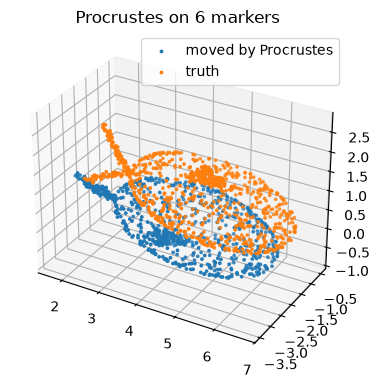

In [10]:
Qm, tm, sm = procrustes(M, M_meas)
print("singular values of centred M'M_meas:", sm)
print(f"det Q = {np.linalg.det(Qm):+.0f}")
print(f"RMS marker residual = {rms(move(M, Qm, tm), M_meas):.4f}")
print(f"RMS fish vs truth   = {rms(move(X, Qm, tm), truth):.4f}")
show(move(X, Qm, tm), truth, labels=["moved by Procrustes", "truth"], title="Procrustes on 6 markers")

**Your answer.** $\det Q = -1$, so Procrustes returned a reflection. The marker RMS is 0.028, about the noise level, so the fit looks fine. But the fish RMS is 1.39. In the plot the fish is mirrored through the plane of the plate: it is upside down and the fin points the wrong way. The six markers cannot see this, because they all lie almost on the mirror plane. The singular values of $\widetilde M^\top\widetilde M_{\text{meas}}$ are $(9.60,\ 2.97,\ 0.0002)$, so the third one is almost zero.

**(b)** Implement `kabsch(X, Y)`, which returns the best **rotation** ($\det Q = +1$) and translation: if $\det(UV^\top) = -1$, use $Q = U\operatorname{diag}(1, 1, -1)V^\top$ (Lecture 5.2, stated without proof). *Predict before running:* by how much will the **squared** marker residual increase compared with (a)? Use the statement in the lecture and the singular values printed in (a). Then compute the increase, the fish RMS and the rotation error.

**Your prediction** *(write it before running the next cell)*: Forcing $\det Q = +1$ changes $\sigma_1+\sigma_2+\sigma_3$ in the formula to $\sigma_1+\sigma_2-\sigma_3$. So the squared residual goes up by $4\sigma_3 = 4\cdot 0.0002 \approx 0.0007$, almost nothing.

In [11]:
def kabsch(X, Y):
    # best rotation (det = +1) and translation with X Q + 1 t' ~ Y
    mx, my = X.mean(0), Y.mean(0)
    U, s, Vt = np.linalg.svd((X - mx).T @ (Y - my))
    d = np.sign(np.linalg.det(U @ Vt))
    Q = U @ np.diag([1, 1, d]) @ Vt
    t = my - mx @ Q
    return Q, t, s

Qk, tk, sk = kabsch(M, M_meas)
r2_p = np.sum((move(M, Qm, tm) - M_meas) ** 2)
r2_k = np.sum((move(M, Qk, tk) - M_meas) ** 2)
print(f"det Q = {np.linalg.det(Qk):+.0f}")
print(f"squared marker residual: Procrustes {r2_p:.6f}, Kabsch {r2_k:.6f}")
print(f"increase = {r2_k - r2_p:.6f};   predicted 4 sigma_3 = {4 * sk[2]:.6f}")
print(f"RMS fish vs truth = {rms(move(X, Qk, tk), truth):.4f}")
print(f"rotation error    = {angle_deg(Qk @ Q_true.T):.3f} deg")

det Q = +1
squared marker residual: Procrustes 0.004564, Kabsch 0.005271
increase = 0.000707;   predicted 4 sigma_3 = 0.000707
RMS fish vs truth = 0.0229
rotation error    = 0.679 deg


**Your answer.** The squared residual increases by 0.000707, exactly $4\sigma_3$. The fish RMS drops from 1.39 to 0.023, and the rotation error is 0.68°. So a very slightly worse fit to the markers gives a much better position for the fish.

**(c)** *Predict, then compute.* How often does Procrustes return a reflection? For $h = 0.01, 0.03, 0.1, 0.3$, repeat the measurement with seeds `1000, ..., 1999` and report the fraction of reflections, together with the smallest singular value $\sigma_3(\widetilde M)$ of the centred marker matrix. Before running, predict how the fraction depends on $h$, and at roughly which $\sigma_3(\widetilde M)$ it should become negligible, given $\text{sd} = 0.02$.

**Your prediction** *(write it before running the next cell)*: A reflection happens when the noise across the plate is about as big as the height spread of the markers, which is $\sigma_3(\widetilde M)$. For $h=0.01$ we have $\sigma_3\approx0.006 < \text{sd}$, so maybe 30–50% reflections (not more than half). The fraction should drop fast as $h$ grows. It should be negligible once $\sigma_3$ is a few times the noise, around 0.05–0.1, so from about $h = 0.1$.

In [12]:
print("    h    sigma_3(M~)   fraction of reflections")
for h in [0.01, 0.03, 0.1, 0.3]:
    Mh = markers(h)
    s3 = np.linalg.svd(Mh - Mh.mean(0), compute_uv=False)[2]
    refl = 0
    for seed in range(1000, 2000):
        Mh_meas = Mh @ Q_true + t_true + 0.02 * np.random.default_rng(seed).standard_normal(Mh.shape)
        Qh, _, _ = procrustes(Mh, Mh_meas)
        refl += np.linalg.det(Qh) < 0
    print(f"{h:5.2f}   {s3:.4f}        {refl / 1000:.3f}")

    h    sigma_3(M~)   fraction of reflections
 0.01   0.0057        0.372
 0.03   0.0170        0.184
 0.10   0.0566        0.001
 0.30   0.1648        0.000


**Your answer.** | $h$ | $\sigma_3(\widetilde M)$ | reflections |
|---|---|---|
| 0.01 | 0.006 | 37% |
| 0.03 | 0.017 | 18% |
| 0.1 | 0.057 | 0.1% |
| 0.3 | 0.165 | 0% |

As predicted, the fraction drops with $h$. Already at $\sigma_3 \approx 0.06$ (about $3\,\text{sd}$) reflections almost never happen. Even at $h = 0.01$ it is below 50%, because the markers still have a little height.

**(d)** The reflection fits the six markers *better* than the true rotation does, yet moves the fish by more than a metre. Explain both facts. What would you change in the marker layout, and why does Kabsch alone not solve the underlying problem?

**Your answer.** **Why the markers fit better:** Procrustes looks over all orthogonal matrices, and rotations are part of that set. So its best fit can only be the same or better. Mirroring through the plate plane moves each marker by only about $2h \approx 0.02$, which is the size of the noise. With this extra freedom the reflection fits the noise a little better (by $4\sigma_3 = 0.0007$ in squared residual).

**Why the fish moves so much:** the fish sticks up to about 1.6 above the plate (from $z=-0.5$ up to the fin at $z\approx1.1$). A mirror moves each point by twice its distance to the plane, so the fish moves by more than a metre.

**What to change:** put the markers at clearly different heights (on posts, or not all on the flat plate), so that $\sigma_3(\widetilde M)$ is many times larger than sd $=0.02$.

**Why Kabsch is not enough:** Kabsch only forbids the mirror. It adds no new information. The markers still barely measure the direction perpendicular to the plate, so the fit in that direction still rests on very little data, and if something really is wrong (for example a scanner with a left-handed frame) we would not notice. The fix belongs in the data, not only in the formula.

---
## B3. Unknown correspondences: iterative closest point

Now the scanner returns a fresh scan of the fish: 800 **different** surface points (another sample of the same surface), in random order, with noise $0.01$. Nothing says which scan point belongs to which model point. ICP alternates two steps that both lower the same objective $\sum_i\min_j\|Q^\top\mathbf x_i + \mathbf t - \mathbf y_j\|^2$:

1. **match**: for each moved model point, find the nearest scan point;
2. **align**: with these matches fixed, find the best rotation and translation (B2's `kabsch`).

It stops when the RMS distance changes by less than `tol`.

In [13]:
def scan(Q, t, n=800, seed=2, sd=0.01, keep=None):
    # a new sample of the fish surface, moved by (Q, t), noisy, shuffled; keep: optional mask on the sample
    P = make_fish(n, seed)
    if keep is not None: P = P[keep(P)]
    r = np.random.default_rng(seed + 50)
    Ys = P @ Q + t + sd * r.standard_normal(P.shape)
    return Ys[r.permutation(len(Ys))]

**(a)** Implement `icp(X, Y, Q, t, iters=60, tol=1e-7, trim=1.0)`, starting from the motion $(Q, \mathbf t)$. It returns the final $Q$, $\mathbf t$ and the history of RMS nearest-neighbour distances (one value per iteration, plus the final one). Build one `cKDTree` on $Y$ outside the loop. With `trim < 1`, the align step uses only the fraction `trim` of matches with the smallest distances (and the RMS is computed over the same matches); you will need this in (e).

In [14]:
def icp(X, Y, Q, t, iters=60, tol=1e-7, trim=1.0):
    tree = cKDTree(Y)                    # built once
    k = int(round(trim * len(X)))        # how many matches we keep

    def match(Q, t):
        d, j = tree.query(X @ Q + t)     # nearest scan point for each moved model point
        keep = np.argsort(d)[:k]         # the k closest matches
        return keep, j[keep], np.sqrt(np.mean(d[keep] ** 2))

    keep, jj, r = match(Q, t)
    hist = [r]
    for _ in range(iters):
        Q, t, _ = kabsch(X[keep], Y[jj])  # align
        keep, jj, r = match(Q, t)        # match
        hist.append(r)
        if abs(hist[-2] - hist[-1]) < tol:
            break
    return Q, t, np.array(hist)

30 iterations; RMS 0.4244 -> 0.2860 -> 0.1972 -> ... -> 0.0911
rotation error 0.53 deg;  RMS never increased: True


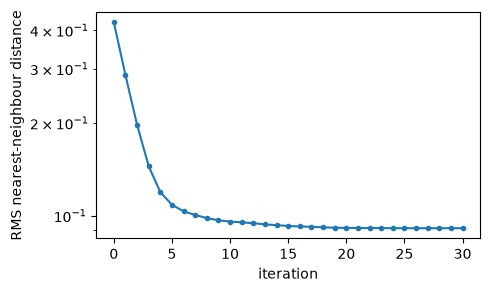

In [15]:
# check: a 30-degree motion, started from the identity and the difference of the means
Q30 = rot([1, 2, 2], 30).T
Ys = scan(Q30, t_true)
Qi, ti, hist = icp(X, Ys, np.eye(3), Ys.mean(0) - X.mean(0))
print(f"{len(hist) - 1} iterations; RMS {hist[0]:.4f} -> {hist[1]:.4f} -> {hist[2]:.4f} -> ... -> {hist[-1]:.4f}")
print(f"rotation error {angle_deg(Qi @ Q30.T):.2f} deg;  RMS never increased: {np.all(np.diff(hist) <= 1e-12)}")
plt.figure(figsize=(5, 3)); plt.semilogy(hist, "o-", ms=3); plt.xlabel("iteration"); plt.ylabel("RMS nearest-neighbour distance")
plt.tight_layout(); plt.show()

**(b)** Two questions about the run above. Why can the RMS never increase from one iteration to the next? And the scan noise is $0.01$: why does the final RMS stop near $0.09$ rather than near $0.01$, although the rotation is recovered to about half a degree?

**Your answer.** **RMS never increases** because both steps can only lower it. *Align:* with the matches fixed, Kabsch finds the best rotation and translation, and the old $(Q,\mathbf t)$ was also allowed, so the sum of squared distances cannot go up. *Match:* every point takes its nearest scan point, which is at most as far as its old partner. So the RMS goes down or stays the same.

**Why 0.09 and not 0.01:** the scan is a *different* sample of the surface, so the exact same point is not in the scan. The nearest scan point is a neighbouring point on the surface, about half the distance between samples away (around 0.09). These gaps point in random directions along the surface, so they cancel out and do not tilt the rotation. That is why the rotation is still good (0.5°).

**(c)** *Predict, then compute.* The **basin of attraction** of ICP is the set of starting errors from which it finds the right answer. Before running, predict the largest rotation angle from which ICP, started at the identity, still succeeds reliably. Then, for angles $0^\circ, 15^\circ, \dots, 180^\circ$ and the 20 random axes below, run ICP from the identity and the difference of the means, and report the fraction of successes (final rotation error below $2^\circ$) and the median final RMS of the failures. Could you detect a failure without knowing the truth?

**Your prediction** *(write it before running the next cell)*: I think ICP works reliably up to about 45–60°. Beyond that, the nearest points will often be on the wrong part of the fish, and ICP will get stuck.

In [16]:
axes = np.random.default_rng(7).standard_normal((20, 3))

In [17]:
angles = np.arange(0, 181, 15)
print(" angle  success   median RMS of failures")
for ang in angles:
    ok, fail_rms = 0, []
    for ax in axes:
        Qa = rot(ax, ang).T
        Ya = scan(Qa, t_true)
        Qi, ti, h = icp(X, Ya, np.eye(3), Ya.mean(0) - X.mean(0))
        if angle_deg(Qi @ Qa.T) < 2:
            ok += 1
        else:
            fail_rms.append(h[-1])
    med = f"{np.median(fail_rms):.3f}" if fail_rms else "  -"
    print(f"{ang:5d}    {ok / 20:.2f}      {med}")

 angle  success   median RMS of failures
    0    1.00        -
   15    1.00        -
   30    1.00        -
   45    1.00        -
   60    1.00        -
   75    1.00        -
   90    0.85      0.195
  105    0.30      0.195
  120    0.15      0.210
  135    0.05      0.199
  150    0.00      0.210
  165    0.00      0.210
  180    0.00      0.210


**Your answer.** Success is 100% up to 75°, 85% at 90°, 30% at 105°, 15% at 120°, and 0% from 150° on. So the basin is bigger than I guessed, about 75–90°. Probably the long, flat shape of the fish still pulls it the right way at fairly large angles. The failed runs end with RMS ≈ 0.20, while successful runs end at ≈ 0.09. **So yes, a failure can be detected without the truth:** a final RMS clearly above the sampling level (0.09) means ICP is stuck in a local minimum.

**(d)** *A better start, from Module 5.* The principal directions of the centred model (the right singular vectors $V_X$) and of the centred scan ($V_Y$) are the axes of the fish in the two frames, each determined only up to sign. Implement `pca_candidates(X, Y)`, which returns the four **rotations** $Q = V_X D V_Y^\top$ with $D$ a diagonal matrix of signs. (Why four and not eight?) Then implement `icp_pca(X, Y)`, which runs ICP from each candidate, with $\mathbf t = \bar{\mathbf y} - Q^\top\bar{\mathbf x}$ in row form, and keeps the run with the smallest final RMS. Repeat the sweep of (c) for angles $0^\circ, 30^\circ, \dots, 180^\circ$.

In [18]:
from itertools import product

def pca_candidates(X, Y):
    Vx = np.linalg.svd(X - X.mean(0), full_matrices=False)[2].T
    Vy = np.linalg.svd(Y - Y.mean(0), full_matrices=False)[2].T
    cands = []
    for d in product([1, -1], repeat=3):
        Q = Vx @ np.diag(d) @ Vy.T
        if np.linalg.det(Q) > 0:         # keep only rotations
            cands.append(Q)
    return cands

def icp_pca(X, Y):
    best = None
    for Q in pca_candidates(X, Y):
        t = Y.mean(0) - X.mean(0) @ Q
        res = icp(X, Y, Q, t)
        if best is None or res[2][-1] < best[2][-1]:
            best = res
    return best

print("number of candidates:", len(pca_candidates(X, Ys)))
print(" angle  success   median RMS of failures")
for ang in np.arange(0, 181, 30):
    ok, fail_rms = 0, []
    for ax in axes:
        Qa = rot(ax, ang).T
        Ya = scan(Qa, t_true)
        Qi, ti, h = icp_pca(X, Ya)
        if angle_deg(Qi @ Qa.T) < 2:
            ok += 1
        else:
            fail_rms.append(h[-1])
    med = f"{np.median(fail_rms):.3f}" if fail_rms else "  -"
    print(f"{ang:5d}    {ok / 20:.2f}      {med}")

number of candidates: 4
 angle  success   median RMS of failures
    0    1.00        -
   30    1.00        -
   60    1.00        -
   90    1.00        -
  120    1.00        -
  150    1.00        -
  180    1.00        -


**Your answer.** **Why four:** $D$ has $2^3 = 8$ sign choices, but $\det Q = \det V_X\cdot\det D\cdot\det V_Y$. Only half of the choices give $\det Q = +1$; the other 4 are reflections. (The signs are free because a singular vector $\mathbf v$ and $-\mathbf v$ are equally valid.)

**Result:** with `icp_pca` the success is 100% for every angle from 0° to 180°. One of the 4 candidates is always close to the true rotation, and ICP converges from there. Picking the smallest final RMS works because the wrong candidates end at a clearly larger RMS. This works because the fish is not symmetric (bent tail, fin) and its principal axes have clearly different lengths (1.30, 0.58, 0.37), so the axes are well defined.

**(e)** *Predict, then compute.* A real scan sees only part of the object, and picks up stray points. The scan below sees only the side of the fish with $y > -0.3$ (in the model frame), and 10% extra points scattered uniformly around it. Start ICP from the identity and the difference of the **medians** (why not the means?), with up to 300 iterations, and sweep `trim` over $1.0, 0.9, \dots, 0.3$. Report the rotation error and the fish RMS against `truth30 = move(X, Q30, t_true)`. Before running, predict which values of `trim` will work, using the fraction of the fish the scanner sees (printed below).

In [19]:
visible = lambda P: P[:, 1] > -0.3
Yv = scan(Q30, t_true, keep=visible)
r = np.random.default_rng(52)
lo, hi = Yv.min(0) - 0.5, Yv.max(0) + 0.5
Yp = np.vstack([Yv, lo + (hi - lo) * r.random((len(Yv) // 10, 3))])
Yp = Yp[r.permutation(len(Yp))]
truth30 = move(X, Q30, t_true)
print(f"scan: {len(Yv)} surface points + {len(Yp) - len(Yv)} stray points; "
      f"the scanner sees {visible(make_fish(800, 2)).mean():.1%} of the fish")

scan: 582 surface points + 58 stray points; the scanner sees 72.8% of the fish


**Your prediction** *(write it before running the next cell)*: The scanner sees 73% of the fish, so only about 73% of the model points have a real partner in the scan. The rest get matched to wrong points and pull the fish away. So `trim` around 0.7 or a bit less should work, while 1.0 and 0.9 should fail or be clearly worse. A very small trim (0.3) may also go wrong, because then too few points are used. **Medians, not means:** stray points pull the mean, but the median mostly ignores a few outliers.

In [20]:
t0 = np.median(Yp, axis=0) - np.median(X, axis=0)
t_mean = Yp.mean(0) - X.mean(0)
ideal = truth30.mean(0) - X.mean(0)      # the shift that would put the centres on top of each other
print(f"start shift error: means {np.linalg.norm(t_mean - ideal):.3f}, medians {np.linalg.norm(t0 - ideal):.3f}")
print(" trim   rot. error (deg)   fish RMS   final NN RMS")
for trim in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3]:
    Qi, ti, h = icp(X, Yp, np.eye(3), t0, iters=300, trim=trim)
    print(f"{trim:4.1f}    {angle_deg(Qi @ Q30.T):8.2f}         {rms(move(X, Qi, ti), truth30):.4f}     {h[-1]:.4f}")

start shift error: means 0.316, medians 0.325
 trim   rot. error (deg)   fish RMS   final NN RMS
 1.0       15.92         0.2810     0.2163
 0.9        7.63         0.1581     0.1467
 0.8        3.05         0.0684     0.0997
 0.7        1.80         0.0321     0.0720
 0.6        1.02         0.0184     0.0584
 0.5        9.14         0.2415     0.0750
 0.4       11.11         0.2828     0.0648
 0.3        5.03         0.1331     0.0450


**Your answer.** | trim | 1.0 | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 | 0.4 | 0.3 |
|---|---|---|---|---|---|---|---|---|
| rotation error (°) | 15.9 | 7.6 | 3.1 | 1.8 | 1.0 | 9.1 | 11.1 | 5.0 |
| fish RMS | 0.28 | 0.16 | 0.07 | 0.03 | 0.02 | 0.24 | 0.28 | 0.13 |

Only `trim` = 0.7 and 0.6 work (error below 2°, best at 0.6 with fish RMS 0.018). That is just under the visible fraction of 0.73, as predicted. Slightly below it works best, because points near the edge of the visible part also get bad matches. Trimming too much (0.5 and below) fails: ICP then fits only a small piece of the surface and can slide along it. Note that the final NN RMS keeps falling as we trim more (0.3 has the smallest), so the RMS alone does not tell us which `trim` is right.

About medians: here both starts are about 0.3 off (means 0.32, medians 0.33), mostly because the scan misses part of the fish, so in this case the median did not really help. In general, though, a few far-away stray points can move the mean a lot and the median hardly at all.

**(f)** *Predict, then measure.* One ICP iteration does three things: query $n$ points in the tree, form the $3\times3$ matrix $\widetilde X^\top\widetilde Y$, and take its SVD; building the tree is done once. Predict how each cost grows with $n$ (model and scan both of size $n$), and which dominates. Then time them, on clouds that are already roughly aligned, for $n = 10^3, 10^4, 10^5$. Finally estimate the time of brute-force matching (all $n^2$ distances) for $n = 10^4$ from a $2000\times10^4$ block.

**Your prediction** *(write it before running the next cell)*: Building the tree: $O(n\log n)$, done once. Query: $n$ points × $O(\log n)$ each $= O(n\log n)$. Forming $\widetilde X^\top\widetilde Y$: $O(n)$ (about $9n$ multiplications). SVD of a $3\times3$ matrix: constant, it does not depend on $n$. So the query dominates. Brute force is $O(n^2)$, much slower.

In [21]:
def best_time(f, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

print("      n     build      query      X'Y (3x3)    SVD 3x3")
for N in [10**3, 10**4, 10**5]:
    XN = make_fish(N, seed=1)
    YN = scan(Q30, t_true, n=N)
    PN = move(XN, Q30, t_true)               # already roughly aligned
    tree = cKDTree(YN)
    _, j = tree.query(PN)
    A, B = PN - PN.mean(0), YN[j] - YN[j].mean(0)
    H = A.T @ B
    tb = best_time(lambda: cKDTree(YN))
    tq = best_time(lambda: tree.query(PN))
    tm_ = best_time(lambda: (PN - PN.mean(0)).T @ (YN[j] - YN[j].mean(0)))
    ts = best_time(lambda: np.linalg.svd(H))
    print(f"{N:7d}  {tb*1e3:8.3f} ms {tq*1e3:8.3f} ms {tm_*1e3:8.3f} ms  {ts*1e3:8.4f} ms")

# brute force for n = 10^4, measured on a 2000 x 10^4 block
N = 10**4
XN, YN = move(make_fish(N, seed=1), Q30, t_true), scan(Q30, t_true, n=N)
blk = XN[:2000]
def brute_block():
    D2 = (blk ** 2).sum(1)[:, None] + (YN ** 2).sum(1)[None, :] - 2 * blk @ YN.T
    return D2.argmin(1)
tbr = best_time(brute_block)
tree = cKDTree(YN)
print(f"brute force block 2000 x 10^4: {tbr*1e3:.1f} ms  ->  full 10^4 x 10^4 about {tbr * N / 2000 * 1e3:.0f} ms")
print(f"tree query for all 10^4 points: {best_time(lambda: tree.query(XN))*1e3:.1f} ms")

      n     build      query      X'Y (3x3)    SVD 3x3
   1000     0.122 ms    0.484 ms    0.056 ms    0.0095 ms
  10000     2.070 ms    6.160 ms    0.434 ms    0.0090 ms
 100000    27.114 ms   81.110 ms    5.555 ms    0.0093 ms
brute force block 2000 x 10^4: 72.5 ms  ->  full 10^4 x 10^4 about 362 ms
tree query for all 10^4 points: 6.1 ms


**Your answer.** | $n$ | build | query | $\widetilde X^\top\widetilde Y$ | SVD $3\times3$ |
|---|---|---|---|---|
| $10^3$ | 0.12 ms | 0.46 ms | 0.06 ms | 0.01 ms |
| $10^4$ | 2.1 ms | 6.1 ms | 0.44 ms | 0.01 ms |
| $10^5$ | 27 ms | 79 ms | 5.8 ms | 0.01 ms |

The query grows about 13× per 10× in $n$, a bit more than linear, as expected for $n\log n$. The $3\times3$ product grows about 10× (linear). The SVD stays at 0.01 ms. **The query dominates**, as predicted. Building the tree costs less than one query and is done once.

Brute force for $n=10^4$: the $2000\times10^4$ block takes about 61 ms, so the full matching would take about 300 ms, against 6 ms with the tree (about 50× slower). Because it is $O(n^2)$, at $n=10^5$ it would take about 30 s against 79 ms.

---
# Extension - attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E2. Shape from a moving camera: Tomasi-Kanade

*This topic was not lectured; the introduction below is all you need.*

A camera moves around a rigid object and tracks $n$ points through $F$ frames. Far from the object the camera is close to **orthographic**: in frame $f$ it sees the point $\mathbf p$ (a column vector in the object frame) at the image coordinates $(\mathbf i_f^\top\mathbf p + a_f,\ \mathbf j_f^\top\mathbf p + b_f)$, where $\mathbf i_f, \mathbf j_f$ are the first two rows of the camera's rotation (two orthonormal vectors) and $(a_f, b_f)$ is a shift. Stack the $2F$ image rows into the **measurement matrix** $W\in\mathbb R^{2F\times n}$ (column $p$ holds the track of point $p$). After subtracting each row's mean,
$$\widetilde W = \underbrace{\begin{pmatrix}\mathbf i_1^\top\\ \mathbf j_1^\top\\ \vdots\\ \mathbf j_F^\top\end{pmatrix}}_{M\ (2F\times3)}\ \underbrace{\begin{pmatrix}\widetilde{\mathbf p}_1 & \cdots & \widetilde{\mathbf p}_n\end{pmatrix}}_{S\ (3\times n)} + \text{noise},$$
so $\widetilde W$ has rank 3 in the absence of noise (Tomasi and Kanade, 1992). The camera motion $M$ and the shape $S$ are both unknown; the SVD recovers them.

In [22]:
P_true = make_fish(300, seed=3)            # the object (unknown to the method)
F = 15
cams = [rot([1, 0, 0], 20 * np.sin(2 * np.pi * f / F)) @ rot([0, 0, 1], -40 + 80 * f / (F - 1)) for f in range(F)]
shifts = np.random.default_rng(8).uniform(-1, 1, (2 * F, 1))

def measurements(sd):
    W = np.vstack([P_true @ C[:2].T for C in cams]).reshape(F, -1, 2).transpose(0, 2, 1).reshape(2 * F, -1)
    return W + shifts + sd * np.random.default_rng(9).standard_normal((2 * F, len(P_true)))

W = measurements(0.003)
print("W:", W.shape)

W: (30, 300)


**(a)** *Predict, then compute.* Centre the rows of $W$ and compute its singular values. Predict how many stand out, and the level of the others, using the noise floor $\text{sd}(\sqrt{m} + \sqrt{n})$ of Notebook A (A2). Compare.

**Your prediction** *(write it before running the next cell)*: Not attempted.

In [23]:
# Not attempted.

**Your answer.** Not attempted.

**(b)** Set $\widehat M = U_3\Sigma_3^{1/2}$ and $\widehat S = \Sigma_3^{1/2}V_3^\top$, so that $\widehat M\widehat S$ is the best rank-3 approximation of $\widetilde W$. Show that $\widehat MA$ and $A^{-1}\widehat S$ fit the data equally well for **every** invertible $3\times3$ matrix $A$. Check numerically that the rows of $\widehat M$ are not pairs of orthonormal vectors, so $\widehat S$ is the shape only up to an unknown linear distortion.

In [24]:
# Not attempted.

**Your answer.** Not attempted.

**(c)** *The metric upgrade.* We want $A$ such that the rows of $M = \widehat MA$ satisfy $\mathbf i_f^\top\mathbf i_f = \mathbf j_f^\top\mathbf j_f = 1$ and $\mathbf i_f^\top\mathbf j_f = 0$. With $L := AA^\top$ these conditions are **linear** in the six entries of the symmetric matrix $L$: for instance $\widehat{\mathbf m}_{2f-1}^\top L\,\widehat{\mathbf m}_{2f-1} = 1$. Set up the $3F\times6$ system, solve it by least squares (`np.linalg.lstsq`), check that $L$ is positive definite, and recover $A$ as its Cholesky factor (Module 4). Then compute $S = A^{-1}\widehat S$ with a triangular solve and check the orthonormality conditions for $M$.

In [25]:
# Not attempted.

**Your answer.** Not attempted.

**(d)** Compare the recovered shape (the rows of $S^\top$) with the true centred object, after aligning them with `procrustes` and with `kabsch` from B1-B2. Which of the two must you use here, and why? (*Hint:* is the mirror image of the object, seen by the mirrored camera, consistent with the same images?) Then mirror the reconstruction, $M \to MD$, $S \to DS$ with $D = \operatorname{diag}(1,1,-1)$: check that it fits the images exactly as well and still satisfies the orthonormality conditions, and align it to the truth in both ways. Repeat for $\text{sd} = 0.03$ and report the RMS shape error relative to the size of the object.

In [26]:
# Not attempted.

**Your answer.** Not attempted.

---
**Before you submit:** run `Kernel -> Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.